# 05 · Weekly Forecasts

**Goal:** Forecast the next unplayed week with Elo, chart ratings by division, and grade every completed week against final scores and the Vegas line.

**Data:** `nflmodel.data.build_games_file()` (refreshed each run for the latest scores), Elo from `nflmodel.elo.run_elo` with `DEFAULT_PARAMS`

**Contents:** 1. Setup & this week's forecast · 2. Elo chart by division · 3. Grade past weeks

## 1. Setup & This Week's Forecast

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from nflmodel.data import build_games_file
from nflmodel.elo import run_elo, DEFAULT_PARAMS, team_history

SEASON = 2026
FORECAST_DIR = Path("../forecasts")

games = build_games_file(2005, SEASON)
elo = run_elo(games, DEFAULT_PARAMS)

def forecast_path(season, week):
    """Where a week's forecast csv lives."""
    return FORECAST_DIR / f"{season}_wk{week:02d}.csv"

def make_forecast(elo, season, week):
    """
    Forecast table for one week. 

    elo:    DataFrame from run_elo
    season: season to forecast
    week:   week to forecast
    """

    fc = elo[(elo["season"] == season) & (elo["week"] == week)].copy()

    hfa = np.where(fc["is_neutral"], DEFAULT_PARAMS["neutral_hfa"], DEFAULT_PARAMS["hfa"])
    fc["pred_spread"] = (fc["elo_home_pre"] - fc["elo_away_pre"] + hfa) / DEFAULT_PARAMS["spread_divisor"]

    fc["matchup"] = fc["away_team"] + " @ " + fc["home_team"]
    fc["home_win_pct"] = (fc["home_prob"] * 100).round(0)
    fc["pred_spread"] = fc["pred_spread"].round(1)

    table = (fc[["matchup", "home_win_pct", "pred_spread", "spread_line"]]
             .sort_values("pred_spread", ascending = False)
             .set_index("matchup"))
    return table

# NExt unplayed week
upcoming = elo[(elo["season"] == SEASON) & (elo["home_win"].isna())]
week = upcoming["week"].min()

table = make_forecast(elo, SEASON, week)
table.to_csv(forecast_path(SEASON, week))

# Heatmap
(table.style
     .background_gradient(subset=["home_win_pct"], cmap="RdYlGn", vmin=0, vmax=100)
     .background_gradient(subset=["pred_spread", "spread_line"], cmap="RdYlGn", vmin=-14, vmax=14)
     .format({"home_win_pct": "{:.0f}%", "pred_spread": "{:+.1f}", "spread_line": "{:+.1f}"}))

Saved 5970 games (2005-2026) to /Users/grantjones/NFL Prediction Model/NFL-model/data/games_clean.parquet


,home_win_pct,pred_spread,spread_line
matchup,,,
TEN @ CIN,84%,+11.3,+10.0
IND @ JAX,79%,+9.2,+8.5
LAC @ LA,77%,+8.4,+6.5
BAL @ BUF,73%,+6.9,+3.5
ARI @ DAL,68%,+5.2,+6.5
CLE @ PIT,67%,+4.9,+3.5
CHI @ SEA,67%,+4.9,+3.0
CAR @ GB,65%,+4.4,+3.5
KC @ DEN,64%,+4.0,-1.5


## 2. Elo Chart by Division

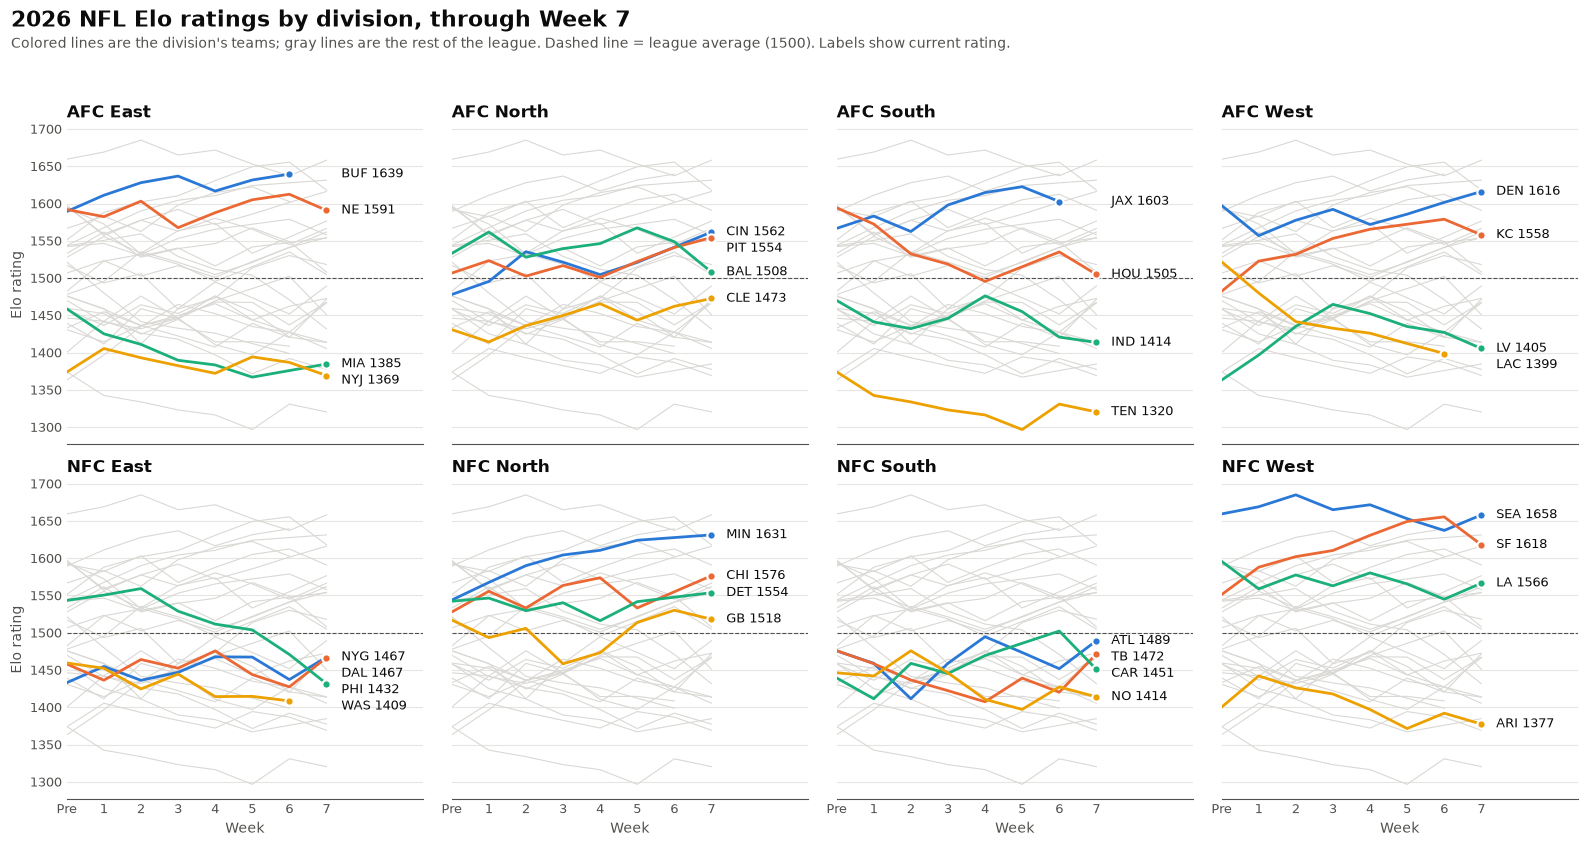

In [28]:
DIVISIONS = {
    "AFC East":  ["BUF", "MIA", "NE", "NYJ"],
    "AFC North": ["BAL", "CIN", "CLE", "PIT"],
    "AFC South": ["HOU", "IND", "JAX", "TEN"],
    "AFC West":  ["DEN", "KC", "LAC", "LV"],
    "NFC East":  ["DAL", "NYG", "PHI", "WAS"],
    "NFC North": ["CHI", "DET", "GB", "MIN"],
    "NFC South": ["ATL", "CAR", "NO", "TB"],
    "NFC West":  ["ARI", "LA", "SEA", "SF"],
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID, CONTEXT = "#0b0b0b", "#52514e", "#e6e5e1", "#d9d8d4"

# 1. Data: one row per team per played game, plus a week-0 preseason point
history = team_history(elo)
season = history[(history["season"] == SEASON) & (history["week"] < week)]

preseason = (season.sort_values("kickoff")
             .groupby("team", as_index=False)
             .first()[["team", "elo_pre"]]
             .rename(columns={"elo_pre": "elo"})
             .assign(week=0))
played = season[["team", "week", "elo_post"]].rename(columns = {"elo_post": "elo"})
ratings = (pd.concat([preseason, played])
           .sort_values(["team", "week"])
           .reset_index(drop=True))
current = ratings.groupby("team")["elo"].last()

# 2. Layout: 2 rows (AFC, NFC) * 4 divisions, shared axes
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), sharex = True, sharey = True)

for ax, (division, teams) in zip(axes.flat, DIVISIONS.items()):

    # 2a. Every other team as faint gray context
    for team, grp in ratings[~ratings["team"].isin(teams)].groupby("team"):
        ax.plot(grp["week"], grp["elo"], color=CONTEXT, linewidth=.8, zorder=1)

    # 2b. League-average reference line
    ax.axhline(1500, color=MUTED, linewidth=.8, linestyle="--", zorder=2)

    # 2c. The division's four teams, best to worst so colors read top to bottom
    order = current[teams].sort_values(ascending = False).index
    ends = []
    for color, team in zip(COLORS, order):
        grp = ratings[ratings["team"] == team]
        ax.plot(grp["week"], grp["elo"], color = color, linewidth = 2, zorder=3)
        ax.plot(grp["week"].iloc[-1], grp["elo"].iloc[-1], marker="o", color=color, 
                markersize=6, markeredgecolor="white", markeredgewidth=1.5, zorder=4)
        ends.append([team, grp["elo"].iloc[-1]])

    # 2d. Directl labels at the line ends, nudged apart so they don't overlap
    min_gap = 22
    for i in range(1, len(ends)):
        if ends[i - 1][1] - ends[i][1] < min_gap:
            ends[i][1] = ends[i-1][1] - min_gap
    for team, y in ends:
        ax.text(week - 0.6, y, f"{team} {current[team]:.0f}", va="center", fontsize=9, color=INK)

     # 2e. Panel styling
    ax.set_title(division, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)
    ax.tick_params(colors=MUTED, length=0, labelsize=9)

# 3. Shared axes and titles
axes[0, 0].set_xlim(0, week + 1.6)
axes[0, 0].set_xticks(range(0, week))
axes[0, 0].set_xticklabels(["Pre"] + [str(w) for w in range(1, week)])
for ax in axes[1]:
    ax.set_xlabel("Week", color=MUTED, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Elo rating", color=MUTED, fontsize=10)

fig.suptitle(f"{SEASON} NFL Elo ratings by division, through Week {week - 1}",
             x=0.01, y=0.99, ha="left", fontsize=16, fontweight="bold", color=INK)
fig.text(0.01, 0.945, "Colored lines are the division's teams; gray lines are the rest of the league. "
         "Dashed line = league average (1500). Labels show current rating.",
         fontsize=10, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.94])

# 4. Save next to the forecast CSV
fig.savefig(FORECAST_DIR / f"{SEASON}_wk{week:02d}_elo.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Grade Past Weeks

In [34]:
def grade_week(season, week):
    """
    Grade one week's forecast against the final scores.

    Uses the saved CSV if there is one (what was actually predicted);
    otherwise reruns the current model for that week.
    """
    path = forecast_path(season, week)
    if path.exists():
        pred, source = pd.read_csv(path), "saved"
    else:
        pred, source = make_forecast(elo, season, week).reset_index(), "rerun"

    # Match each forecast to its final score
    pred[["away_team", "home_team"]] = pred["matchup"].str.split(" @ ", expand=True)
    final = games[(games["season"] == season) & (games["week"] == week) & games["result"].notna()]
    g = pred.merge(final[["home_team", "away_team", "home_score", "away_score", "result"]],
                   on=["home_team", "away_team"])

    home, away = g["home_team"], g["away_team"]

    # Straight up: did Elo's favorite win?
    g["elo_pick"] = np.where(g["home_win_pct"] >= 50, home, away)
    g["pick_conf"] = np.where(g["elo_pick"] == home, g["home_win_pct"], 100 - g["home_win_pct"])
    g["winner"] = np.select([g["result"] > 0, g["result"] < 0], [home, away], "TIE")
    g["pick_result"] = np.select([g["winner"] == "TIE", g["elo_pick"] == g["winner"]],
                                 ["Push", "W"], "L")

    # Against the spread: Elo's side vs the Vegas line
    # (both spreads are home margin: +3 means home favored by 3)
    elo_side = np.sign(g["pred_spread"] - g["spread_line"])   # +1 home, -1 away, 0 no pick
    cover = np.sign(g["result"] - g["spread_line"])                 # +1 home covered, -1 away, 0 push
    g["ats_result"] = np.select([elo_side == 0, cover == 0, elo_side == cover],
                                ["No pick", "Push", "W"], "L")

    # How far each spread missed the final margin
    g["elo_error"] = (g["pred_spread"] - g["result"]).abs()
    g["vegas_error"] = (g["spread_line"] - g["result"]).abs()

    # Final score as "WINNER 30-24"
    hi = np.maximum(g["home_score"], g["away_score"]).astype(str)
    lo = np.minimum(g["home_score"], g["away_score"]).astype(str)
    g["final"] = g["winner"].where(g["winner"] != "TIE", "Tie") + " " + hi + "-" + lo

    g["season"], g["week"], g["source"] = season, week, source
    return g


def record(results):
    """'W-L' or 'W-L-P' from a Series of W / L / Push."""
    w, l, p = [(results == r).sum() for r in ["W", "L", "Push"]]
    return f"{w}-{l}" + (f"-{p}" if p else "")


def week_summary(d):
    """One summary row for a set of graded games."""
    return pd.Series({
        "Forecast":         d["source"].iloc[0] if d["source"].nunique() == 1 else "",
        "Games":            len(d),
        "Picks":            record(d["pick_result"]),
        "Pick %":           (d["pick_result"] == "W").sum() / (d["pick_result"] != "Push").sum(),
        "ATS":              record(d["ats_result"]),
        "Elo miss (pts)":   d["elo_error"].mean(),
        "Vegas miss (pts)": d["vegas_error"].mean(),
    })


def color_result(v):
    """Green for W, red for L, gray otherwise."""
    return {"W": "color: #1a7f37; font-weight: bold",
            "L": "color: #cf222e; font-weight: bold"}.get(v, "color: #52514e")


# 1. Grade every completed week and save the full record
graded = pd.concat([grade_week(SEASON, wk) for wk in range(1, week)], ignore_index=True)
graded.to_csv(FORECAST_DIR / f"{SEASON}_graded.csv", index=False)

# 2. Season summary, one row per week plus a season total
summary = graded.groupby("week").apply(week_summary, include_groups=False)
summary.loc["Season"] = week_summary(graded)
summary.index.name = None

display(summary.style
        .format({"Pick %": "{:.1%}", "Elo miss (pts)": "{:.1f}", "Vegas miss (pts)": "{:.1f}"})
        .set_caption(f"{SEASON} forecast record"))

# 3. Game-by-game results for the most recent week
last = week - 1
detail = (graded[graded["week"] == last]
          [["matchup", "elo_pick", "pick_conf", "final", "pick_result",
            "pred_spread", "spread_line", "result", "ats_result"]]
          .rename(columns={"elo_pick": "Elo pick", "pick_conf": "Win %", "final": "Final",
                           "pick_result": "Pick", "pred_spread": "Elo spread",
                           "spread_line": "Vegas spread", "result": "Home margin",
                           "ats_result": "ATS"})
          .set_index("matchup"))
detail.index.name = None

display(detail.style
        .map(color_result, subset=["Pick", "ATS"])
        .format({"Win %": "{:.0f}%", "Elo spread": "{:+.1f}",
                 "Vegas spread": "{:+.1f}", "Home margin": "{:+d}"})
        .set_caption(f"Week {last} results"))


,Forecast,Games,Picks,Pick %,ATS,Elo miss (pts),Vegas miss (pts)
1,rerun,16,10-6,62.5%,6-9-1,12.2,11.3
2,rerun,16,10-6,62.5%,8-8,12.0,11.8
3,rerun,16,12-4,75.0%,8-6-2,7.9,8.1
4,rerun,16,8-8,50.0%,9-5-2,7.0,7.3
5,rerun,15,9-5-1,64.3%,8-6-1,9.5,10.4
6,rerun,14,7-7,50.0%,4-10,7.6,6.6
7,saved,13,7-6,53.8%,7-5-1,11.5,10.7
Season,,106,63-42-1,60.0%,50-49-7,9.7,9.5


,Elo pick,Win %,Final,Pick,Elo spread,Vegas spread,Home margin,ATS
IND @ MIN,MIN,81%,MIN 16-10,W,+10.0,+6.5,+6,L
NYG @ HOU,HOU,72%,NYG 27-21,L,+6.5,+10.0,-6,W
TB @ CAR,CAR,67%,TB 43-13,L,+5.0,+3.0,-30,L
KC @ SEA,SEA,66%,SEA 20-3,W,+4.5,+3.0,+17,W
DAL @ PHI,PHI,64%,DAL 38-21,L,+4.0,-4.5,-17,L
CIN @ BAL,BAL,61%,CIN 35-13,L,+3.0,-2.5,-22,L
GB @ DET,DET,59%,DET 20-17,W,+2.5,+3.0,+3,Push
MIA @ NYJ,NYJ,58%,MIA 28-25,L,+2.0,+4.5,-3,W
CLE @ TEN,CLE,62%,CLE 27-24,W,-3.5,-2.5,-3,W
LA @ LV,LA,63%,LA 35-21,W,-3.5,-3.0,-14,W
